# Practical 1 — Data preparation and exploratory analysis
## Hotel Booking Demand: will a booking be cancelled?

**Assignment 4** · Aziz Abdulin · repeats the course practical on data preparation and EDA on a new dataset.

**Dataset.** Hotel Booking Demand (Antonio, Almeida & Nunes, *Data in Brief* 22, 2019; CC BY 4.0): 119,390 bookings
of a city hotel and a resort hotel in Portugal with arrival dates from July 2015 to August 2017, 32 columns.
Target: `is_canceled`. The same table is used in Practicals 2 and 3.

**Plan.** 1) first look · 2) data quality: missing values, duplicates, impossible values · 3) leakage audit — which
columns are only known after the outcome · 4) feature engineering · 5) EDA · 6) time-based split · 7) conclusions.

In [1]:
import json, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
for d in (DATA, FIG, RES): d.mkdir(exist_ok=True)
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
if not (DATA / "hotels.csv").exists():
    urllib.request.urlretrieve(URL, DATA / "hotels.csv")
raw = pd.read_csv(DATA / "hotels.csv")
print(raw.shape)
raw.head(3)

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


## 1. First look

In [2]:
print(f"bookings: {len(raw):,}  columns: {raw.shape[1]}")
print(f"cancellation rate: {raw.is_canceled.mean():.3f}")
print(raw.groupby("hotel").is_canceled.agg(["size", "mean"]).round(3))
print(raw.groupby("arrival_date_year").size())

bookings: 119,390  columns: 32
cancellation rate: 0.370
               size   mean
hotel                     
City Hotel    79330  0.417
Resort Hotel  40060  0.278
arrival_date_year
2015    21996
2016    56707
2017    40687
dtype: int64


37 % of bookings are cancelled — the classes are imbalanced, but not extremely (unlike rare-event problems).

## 2. Data quality

### 2.1 Column audit

In [3]:
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                      "missing %": (raw.isna().mean() * 100).round(2), "unique": raw.nunique(),
                      "example": raw.iloc[0]})
audit.sort_values("missing", ascending=False)

,dtype,missing,missing %,unique,example
company,float64,112593,94.31,352,NaN
agent,float64,16340,13.69,333,NaN
country,str,488,0.41,177,PRT
children,float64,4,0.00,5,0.0
reserved_room_type,str,0,0.00,10,C
assigned_room_type,str,0,0.00,12,C
booking_changes,int64,0,0.00,21,3
deposit_type,str,0,0.00,3,No Deposit
hotel,str,0,0.00,2,Resort Hotel
previous_cancellations,int64,0,0.00,15,0


### 2.2 Missing values — what they mean

* `company` (94 % missing) and `agent` (14 %) are missing **by design**: the booking was made without a company or a
  travel agent. A missing value is information, so it becomes a flag `has_company` / `has_agent`, not an imputed number.
* `country` (488 rows): unknown → own category `Unknown`.
* `children` (4 rows): no children recorded → 0.

In [4]:
df = raw.copy()
df["has_agent"] = df.agent.notna().astype(int)
df["has_company"] = df.company.notna().astype(int)
df["country"] = df.country.fillna("Unknown")
df["children"] = df.children.fillna(0).astype(int)
df["meal"] = df.meal.replace("Undefined", "SC")          # dataset documentation: Undefined and SC both mean no meal
print(df[["has_agent", "has_company"]].mean().round(3).to_dict())

{'has_agent': 0.863, 'has_company': 0.057}


### 2.3 Duplicates

A quarter of the rows are exact copies of another row. The table has no booking id, so identical rows can be
separate bookings of the same group (same agent, dates, room type and price). Before deciding, check whether
duplicates differ from unique rows.

In [5]:
dup = raw.duplicated(keep=False)
print(f"rows that have an identical twin: {dup.sum():,} ({dup.mean():.1%}); extra copies: {raw.duplicated().sum():,}")
cmp = pd.DataFrame({"duplicated rows": raw[dup].agg({"is_canceled": "mean", "lead_time": "median", "agent": lambda s: s.notna().mean()}),
                    "unique rows": raw[~dup].agg({"is_canceled": "mean", "lead_time": "median", "agent": lambda s: s.notna().mean()})})
cmp.index = ["cancellation rate", "median lead time, days", "share via agent"]
print(cmp.round(3))
print(raw[dup].market_segment.value_counts(normalize=True).head(4).round(3))

rows that have an identical twin: 40,165 (33.6%); extra copies: 31,994
                        duplicated rows  unique rows
cancellation rate                 0.584        0.262
median lead time, days          133.000       46.000
share via agent                   0.870        0.860
market_segment
Groups           0.416
Offline TA/TO    0.304
Online TA        0.206
Corporate        0.037
Name: proportion, dtype: float64


Duplicated rows are a different population — mostly group and agency bookings with long lead times and a much higher
cancellation rate. Dropping them would remove real bookings and change the target. **Decision: keep them.** The
danger they bring is a random train/test split: copies of one group would land on both sides and inflate the score.
The time-based split in §6 keeps a group together.

### 2.4 Impossible and extreme values

bookings with 0 guests: 180
negative price (adr < 0): 1  zero price: 1959
adr quantiles: {0.5: 94.6, 0.99: 252.0, 0.999: 326.2, 1.0: 5400.0}


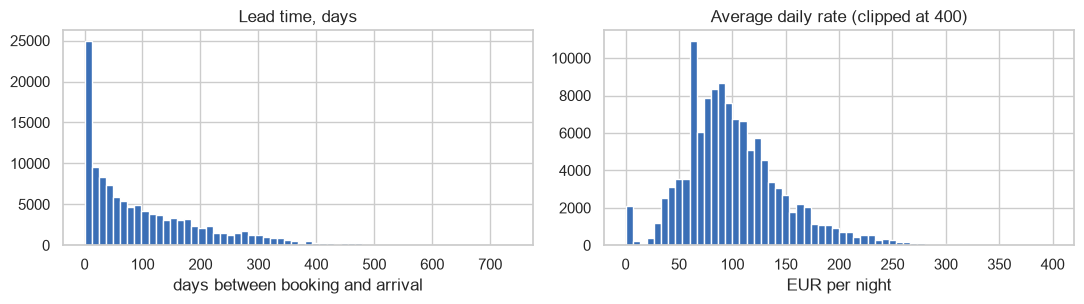

In [6]:
guests = df.adults + df.children + df.babies
print("bookings with 0 guests:", int((guests == 0).sum()))
print("negative price (adr < 0):", int((df.adr < 0).sum()), " zero price:", int((df.adr == 0).sum()))
print("adr quantiles:", df.adr.quantile([.5, .99, .999, 1]).round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(df.lead_time, bins=60, color="#3b6fb6"); ax[0].set(title="Lead time, days", xlabel="days between booking and arrival")
ax[1].hist(df.adr.clip(0, 400), bins=60, color="#3b6fb6"); ax[1].set(title="Average daily rate (clipped at 400)", xlabel="EUR per night")
plt.tight_layout(); plt.savefig(FIG / "p1_distributions.png", dpi=120); plt.show()

In [7]:
before = len(df)
df = df[(guests > 0) & (df.adr >= 0) & (df.adr < 1000)].copy()     # 0 guests or negative/absurd price = entry errors
print(f"dropped {before - len(df)} rows ({(before - len(df)) / before:.2%})")

dropped 182 rows (0.15%)


Zero-guest bookings and a negative price are impossible; one booking at 5,400 EUR per night is an entry error
(the 99.9th percentile is about 250 EUR). Rows with free stays (adr = 0, complimentary rooms) are kept — they are
real. Long right tails (`lead_time`, `adr`) are kept and handled later by scaling or by tree models.

## 3. Leakage audit

The model must work **at the moment of booking**. A column whose value is only known later — after the guest arrives
or cancels — makes the model look perfect on historical data and useless in production. Quick test: how well does
each column *alone* predict cancellation? Scores are measured out of time (category means learnt on 2015–2016,
ROC-AUC on 2017), so high-cardinality columns cannot win by memorising.

In [8]:
d = df.copy()
d["status_date_minus_arrival"] = (pd.to_datetime(d.reservation_status_date)
    - pd.to_datetime(d.arrival_date_year.astype(str) + "-" + d.arrival_date_month + "-" + d.arrival_date_day_of_month.astype(str))).dt.days
d["room_changed"] = (d.reserved_room_type != d.assigned_room_type).astype(int)
early, late = d.arrival_date_year < 2017, d.arrival_date_year == 2017

def solo_auc(col):
    x = d[col]
    if x.dtype.kind in "if" and x.nunique() > 20:              # numeric: the value itself is the score
        s = x[late].fillna(x[early].median())
        a = roc_auc_score(d.is_canceled[late], s)
        return max(a, 1 - a)
    means = d[early].groupby(x[early].astype(str)).is_canceled.mean()
    s = x[late].astype(str).map(means).fillna(d.is_canceled[early].mean())
    return roc_auc_score(d.is_canceled[late], s)

cols = [c for c in d.columns if c not in ("is_canceled", "reservation_status_date", "arrival_date_year")]
leak = pd.Series({c: solo_auc(c) for c in cols}).sort_values(ascending=False).round(3)
leak.head(12)

reservation_status           1.000
status_date_minus_arrival    1.000
country                      0.668
lead_time                    0.655
deposit_type                 0.630
total_of_special_requests    0.620
market_segment               0.599
customer_type                0.580
booking_changes              0.571
distribution_channel         0.570
assigned_room_type           0.560
room_changed                 0.555
dtype: float64

In [9]:
print(pd.crosstab(d.reservation_status, d.is_canceled))
print(d.groupby("room_changed").is_canceled.agg(["mean", "size"]).round(3))
print(d.groupby(d.required_car_parking_spaces.clip(upper=1)).is_canceled.agg(["mean", "size"]).round(3))

is_canceled             0      1
reservation_status              
Canceled                0  42992
Check-Out           75010      0
No-Show                 0   1206
               mean    size
room_changed               
0             0.416  104413
1             0.054   14795
                              mean    size
required_car_parking_spaces               
0                            0.395  111799
1                            0.000    7409


* `reservation_status` (Canceled / No-Show / Check-Out) **is the target** written in words: ROC-AUC 1.0.
* `reservation_status_date` is the date of that status; relative to the arrival date it says when the booking ended —
  before arrival means a cancellation.
* `assigned_room_type` is set at check-in. A guest who cancelled never gets a different room, so "room changed" is
  almost always a non-cancelled booking (cancellation rate 5 % vs 42 %) — known only after the outcome.
* `required_car_parking_spaces`: **not a single** booking with a parking space was cancelled (0 % of 7,400). A feature
  that makes one outcome impossible is a red flag: the space is most likely recorded when the guest arrives.
* `booking_changes` counts amendments made **until** check-in or cancellation — also accumulated after the booking moment.

These five are dropped. `deposit_type` also scores high, but it is fixed at booking time, so it stays (§5 shows why
it is so predictive). `country` is the strongest remaining column (Portugal 57 % cancelled vs 24 % for other
countries); it is kept, but in a real project one should ask the hotel when this field is filled in — if at check-in,
it would be a leak too.

## 4. Feature engineering

In [10]:
LEAKS = ["reservation_status", "reservation_status_date", "assigned_room_type", "booking_changes", "required_car_parking_spaces"]
df = df.drop(columns=LEAKS)
months = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                      "August", "September", "October", "November", "December"], 1)}
df["arrival_date"] = pd.to_datetime(dict(year=df.arrival_date_year, month=df.arrival_date_month.map(months), day=df.arrival_date_day_of_month))
df["booking_date"] = df.arrival_date - pd.to_timedelta(df.lead_time, unit="D")
df["arrival_month"] = df.arrival_date.dt.month
df["arrival_weekday"] = df.arrival_date.dt.weekday
df["booking_month"] = df.booking_date.dt.month
df["total_nights"] = df.stays_in_weekend_nights + df.stays_in_week_nights
df["weekend_share"] = np.where(df.total_nights > 0, df.stays_in_weekend_nights / df.total_nights.clip(lower=1), 0)
df["total_guests"] = df.adults + df.children + df.babies
df["has_kids"] = ((df.children + df.babies) > 0).astype(int)
df["adr_per_guest"] = df.adr / df.total_guests
df["log_lead_time"] = np.log1p(df.lead_time)
df["repeat_history"] = df.previous_cancellations + df.previous_bookings_not_canceled
top_c = df.country.value_counts().index[:15]
df["country_top"] = np.where(df.country.isin(top_c), df.country, "Other")
top_a = df.agent.value_counts().index[:20]
df["agent_top"] = np.where(df.agent.isin(top_a), "a" + df.agent.fillna(0).astype(int).astype(str), np.where(df.agent.isna(), "none", "other"))
print(df.shape)
df[["arrival_date", "booking_date", "total_nights", "total_guests", "adr_per_guest", "country_top", "agent_top"]].head()

(119208, 43)


,arrival_date,booking_date,total_nights,total_guests,adr_per_guest,country_top,agent_top
0,2015-07-01,2014-07-24,0,2,0.0,PRT,none
1,2015-07-01,2013-06-24,0,2,0.0,PRT,none
2,2015-07-01,2015-06-24,1,1,75.0,GBR,none
3,2015-07-01,2015-06-18,1,1,75.0,GBR,other
4,2015-07-01,2015-06-17,2,2,49.0,GBR,a240


Dates are rebuilt from three columns, so the booking date (arrival − lead time) and weekday become available. Ratios
(`adr_per_guest`, `weekend_share`) describe the trip better than raw counts. Countries and agents have hundreds of
values; the 15 most common countries and 20 most common agents keep their own category, the rest become `Other`.

## 5. Exploratory analysis

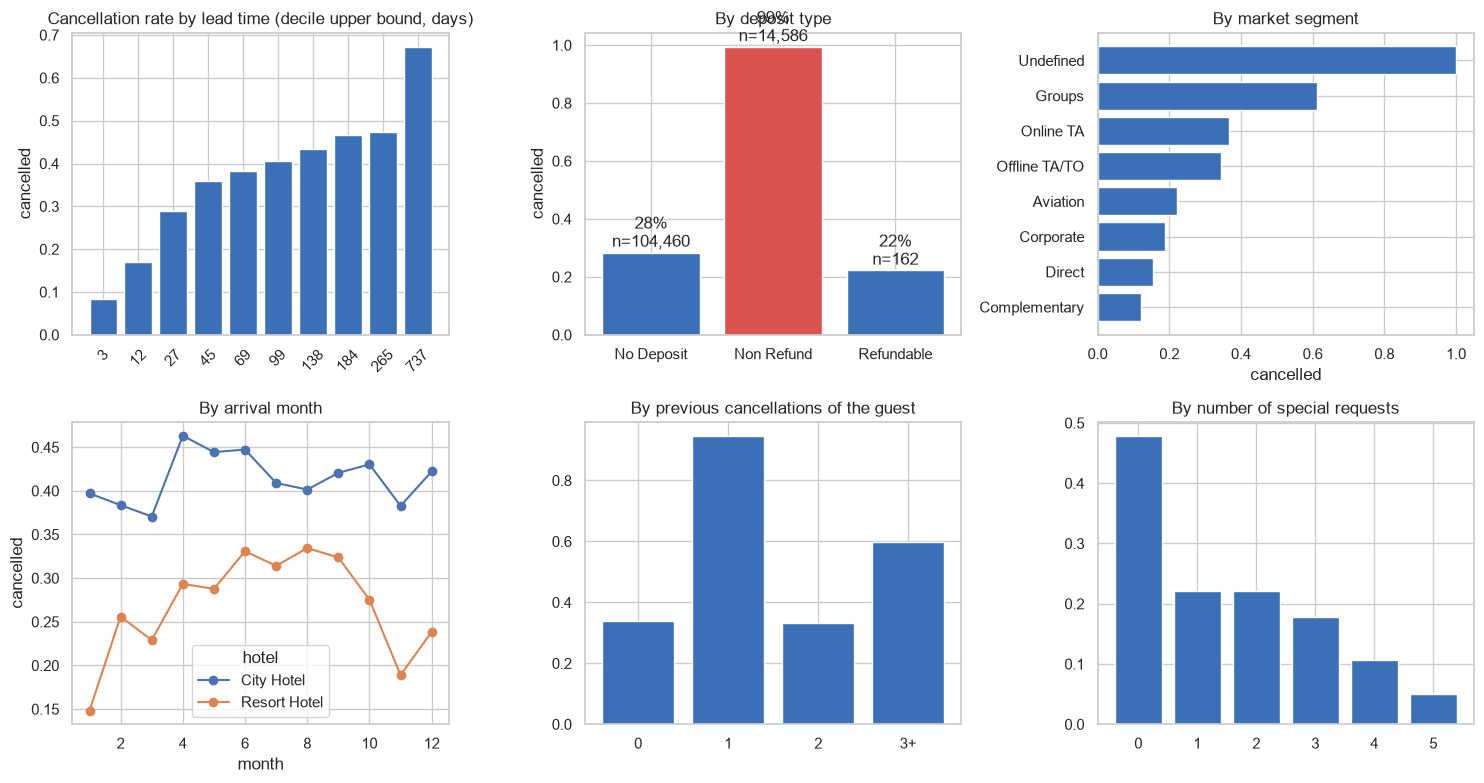

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
q = pd.qcut(df.lead_time, 10, duplicates="drop")
r = df.groupby(q, observed=True).is_canceled.mean()
ax[0, 0].bar(range(len(r)), r.values, color="#3b6fb6"); ax[0, 0].set_xticks(range(len(r)), [f"{int(i.right)}" for i in r.index], rotation=45)
ax[0, 0].set(title="Cancellation rate by lead time (decile upper bound, days)", ylabel="cancelled")
r = df.groupby("deposit_type").is_canceled.agg(["mean", "size"])
ax[0, 1].bar(r.index, r["mean"], color=["#3b6fb6", "#d9534f", "#3b6fb6"]); ax[0, 1].set(title="By deposit type", ylabel="cancelled")
for i, (m, n) in enumerate(zip(r["mean"], r["size"])): ax[0, 1].text(i, m + .02, f"{m:.0%}\nn={n:,}", ha="center")
r = df.groupby("market_segment").is_canceled.mean().sort_values()
ax[0, 2].barh(r.index, r.values, color="#3b6fb6"); ax[0, 2].set(title="By market segment", xlabel="cancelled")
r = df.groupby(["arrival_month", "hotel"]).is_canceled.mean().unstack()
r.plot(ax=ax[1, 0], marker="o"); ax[1, 0].set(title="By arrival month", xlabel="month", ylabel="cancelled")
r = df.groupby(df.previous_cancellations.clip(upper=3)).is_canceled.mean()
ax[1, 1].bar(["0", "1", "2", "3+"], r.values, color="#3b6fb6"); ax[1, 1].set(title="By previous cancellations of the guest")
r = df.groupby("total_of_special_requests").is_canceled.mean()
ax[1, 2].bar(r.index.astype(str), r.values, color="#3b6fb6"); ax[1, 2].set(title="By number of special requests")
plt.tight_layout(); plt.savefig(FIG / "p1_eda.png", dpi=120); plt.show()

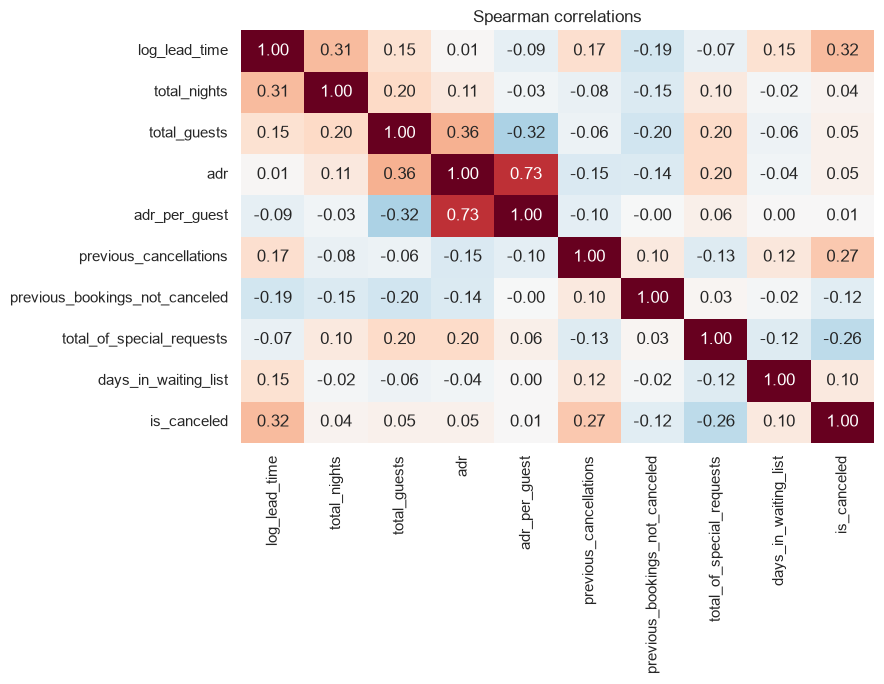

In [12]:
num = ["log_lead_time", "total_nights", "total_guests", "adr", "adr_per_guest", "previous_cancellations",
       "previous_bookings_not_canceled", "total_of_special_requests", "days_in_waiting_list", "is_canceled"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Spearman correlations"); plt.tight_layout(); plt.savefig(FIG / "p1_corr.png", dpi=120); plt.show()

In [13]:
nr = df[df.deposit_type == "Non Refund"]
print(f"Non Refund bookings: {len(nr):,}, cancelled {nr.is_canceled.mean():.1%}")
print("share from Portugal:", round((nr.country == "PRT").mean(), 3), " via agent:", round(nr.has_agent.mean(), 3),
      " median lead time:", nr.lead_time.median(), "vs", df.lead_time.median())

Non Refund bookings: 14,586, cancelled 99.4%
share from Portugal: 0.972  via agent: 0.859  median lead time: 183.0 vs 69.0


What the data says before any model:

* **Lead time** is the strongest simple signal: bookings made 0–3 days ahead are cancelled 8 % of the time, more
  than 265 days ahead — 67 %.
* **Non-refundable deposits are cancelled 99 % of the time** — the opposite of intuition. These are almost all
  Portuguese agency/group bookings made months ahead (block reservations that are released). The feature is
  legitimate (known at booking), but it describes a booking channel, not customer behaviour.
* Guests with exactly **one previous cancellation** cancel 94 % of the time (6,048 bookings — mostly repeated group
  bookings). Bookings **without special requests** are cancelled in 48 % of cases, with one request — 22 %, with five —
  5 %: requests signal commitment.
* The city hotel is cancelled more often than the resort (42 % vs 28 %); cancellations peak for April–June arrivals
  (40–42 %) and are lowest in January and November (31 %).
* Numeric features are weakly correlated with each other, so there is no strong redundancy.

## 6. Time-based split

A model trained on the past is used on the future, so the split follows arrival dates: **train** — arrivals until
the end of 2016, **validation** — January–April 2017 (model and threshold choice), **test** — May–August 2017
(touched once at the end). Booking groups stay inside one period.

In [14]:
df["split"] = np.select([df.arrival_date < "2017-01-01", df.arrival_date < "2017-05-01"], ["train", "val"], "test")
sp = df.groupby("split", sort=False).agg(rows=("is_canceled", "size"), cancel_rate=("is_canceled", "mean"),
      first=("arrival_date", "min"), last=("arrival_date", "max"))
sp["cancel_rate"] = sp.cancel_rate.round(3)
sp

,rows,cancel_rate,first,last
split,,,,
train,78589,0.362,2015-07-01,2016-12-31
val,18442,0.365,2017-01-01,2017-04-30
test,22177,0.406,2017-05-01,2017-08-31


In [15]:
NUM = ["lead_time", "log_lead_time", "arrival_month", "arrival_weekday", "booking_month", "arrival_date_week_number",
       "stays_in_weekend_nights", "stays_in_week_nights", "total_nights", "weekend_share", "adults", "children", "babies",
       "total_guests", "adr", "adr_per_guest", "previous_cancellations", "previous_bookings_not_canceled", "repeat_history",
       "days_in_waiting_list", "total_of_special_requests"]
BIN = ["is_repeated_guest", "has_agent", "has_company", "has_kids"]
CAT = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type", "deposit_type", "customer_type",
       "country_top", "agent_top"]
keep = NUM + BIN + CAT + ["is_canceled", "split", "arrival_date"]
df[keep].to_parquet(DATA / "hotels_clean.parquet", index=False)
json.dump({"num": NUM, "bin": BIN, "cat": CAT, "target": "is_canceled", "dropped_leaks": LEAKS}, open(RES / "p1_features.json", "w"), indent=1)
print(f"saved {len(df):,} rows, {len(NUM) + len(BIN) + len(CAT)} features")

saved 119,208 rows, 34 features


## 7. Conclusions

1. **Missing values carry meaning.** 94 % of `company` and 14 % of `agent` are empty because the booking was made
   without them; they became flags instead of imputed numbers. Only 182 rows (0.15 %) were impossible — no guests,
   negative or absurd price — and were removed.
2. **Duplicates are real bookings, not noise.** 27 % of rows repeat another row; these are group and agency bookings
   cancelled 58 % of the time against 26 % for unique rows. Removing them would bias the target, so they stay, and the
   split is made by time so a group never sits in both train and test.
3. **Five columns leak the outcome** and were dropped: the reservation status and its date (ROC-AUC 1.0 on their own),
   the assigned room type, the number of booking changes and parking spaces (0 % cancellations among 7,409 bookings
   with parking). Without this audit any model would look perfect and fail in use.
4. **Legitimate signals are clear even without a model:** lead time (8 % → 67 % cancelled from the shortest to the
   longest decile), deposit type (non-refundable — 99 %, a sales channel effect), country, special requests and
   previous cancellations.
5. **Result:** a clean table of 119,208 bookings and 34 features saved for Practicals 2–3, split by arrival date into
   train 78,589 / validation 18,442 / test 22,177. The test period (summer 2017) has more cancellations (40.6 % vs
   36.2 % in train) — a realistic shift the models will have to cope with.